# Sentence-level Bottleneck Decomposition

**Feeds:** RQ3 -- where the span/attribute ceiling actually sits.

Notebooks 02 to 04 measure *how much* the pipeline gets wrong. None of them can
say *which stage* is responsible, because the document-level regime asks the
model for participants and their types in a single query: a missing participant
and a mistyped participant arrive indistinguishable from one another in the same
answer.

The sentence-level regime removes that ambiguity. It splits the task into three
separately-logged stages -- **detection** (does this sentence contain a narrative
participant?), **extraction** (which spans are they?) and **classification**
(what type is each span?) -- and records the intermediate state of every sentence
in `results/sentence_level/overview/`. Every gold participant that the pipeline
fails to report can therefore be charged to the stage that lost it:

1. the detector rejected the sentence the participant lives in, so extraction was
   never given the chance;
2. the detector accepted the sentence but extraction did not return the span;
3. extraction returned the span but classification assigned the wrong type.

Losses of kind 1 and 2 are **span-level** failures, and set the ceiling that no
amount of classification skill can lift. Losses of kind 3 are **attribute-level**
failures, and sit below that ceiling. Quantifying the split is the whole point of
this notebook, and it is the direct answer to RQ3.

**Scope.** The sentence-level experiment covers a single model, `qwen3_14b`, at a
fixed temperature of 0.3, in both languages, under two prompt conditions:
`sent_exp` (one-shot example) and `sent_def_exp` (example plus the definition of
narrative participant, with self-reported confidences). All four cells are
analysed. Scores are strict span-level throughout, computed by the same code as
every other notebook in this package.

In [1]:
import sys

sys.path.insert(0, ".")

import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import _common as c

MODEL = "qwen3_14b"
VARIATION = "temp0.3_nodelim_norole_nocot"
CONDITIONS = ["sent_exp", "sent_def_exp"]
OVERVIEW_DIR = c.RESULTS_DIR / "sentence_level" / "overview"

# One colour per pipeline stage, reused by every figure below so a stage keeps
# its identity across the notebook. Okabe-Ito, consistent with _common.py.
STAGE_COLORS = {
    "correct": "#009E73",
    "wrong type": "#E69F00",
    "not extracted": "#D55E00",
    "sentence rejected": "#CC79A7",
    "unlocated": "#999999",
}
CONDITION_COLORS = {"sent_exp": "#0072B2", "sent_def_exp": "#D55E00"}

## Loading the per-sentence record

`results/sentence_level/overview/<language>/<model>/participants/<condition>/<variation>/`
holds one JSON per document, and that JSON -- not the summary CSV beside it -- is
the primary record: it carries the sentence text, the detector's yes/no verdict,
the list of extracted spans and the type assigned to each. Everything below is
re-derived from those files so that the stage attribution and the scores it is
compared against come from the same source.

In [2]:
def overview_dir(language: str, condition: str) -> Path:
    return OVERVIEW_DIR / language / MODEL / "participants" / condition / VARIATION


def load_sentences(language: str, condition: str) -> pd.DataFrame:
    """One row per sentence, with the state of all three pipeline stages."""
    rows = []
    for path in sorted(overview_dir(language, condition).glob("lusa_*.json")):
        record = json.loads(path.read_text(encoding="utf-8"))
        for sentence in record["sentences"]:
            extracted = sentence.get("extracted") or []
            classified = sentence.get("participants") or {}
            rows.append({
                "language": language,
                "condition": condition,
                "doc_id": record["doc_id"],
                "sentence_id": sentence["sentence_id"],
                "text": sentence["full_sentence"],
                "detected": str(sentence.get("detection", "")).lower().startswith("y"),
                # The raw list can repeat a span many times over (see the
                # artefact-integrity section); the pipeline scores unique spans,
                # so both counts are kept.
                "n_extracted_raw": len(extracted),
                "extracted": sorted(set(extracted)),
                "classified": dict(classified),
            })
    return pd.DataFrame(rows)


sentences = pd.concat(
    [load_sentences(language, condition)
     for language in c.LANGUAGE_ORDER for condition in CONDITIONS],
    ignore_index=True,
)

# Strict span-level tp/fp/fn rows for the same runs, from the shared evaluator.
detailed = pd.concat(
    [c.load_detailed("sentence_level/cls", language).assign(language=language)
     for language in c.LANGUAGE_ORDER],
    ignore_index=True,
)
detailed = c.add_run_config_columns(detailed)
detailed["condition"] = "sent_" + detailed["base_template"].str.split("_", n=1).str[1]
detailed = c.coarsen_types(detailed)

print(sentences.groupby(["language", "condition"]).agg(
    docs=("doc_id", "nunique"), sentences=("sentence_id", "size"),
    detected=("detected", "sum"),
).to_string())
print()
print(detailed.groupby(["language", "condition", "result"]).size().unstack("result").to_string())

                         docs  sentences  detected
language   condition                              
english    sent_def_exp    96        517       478
           sent_exp        96        613       539
portuguese sent_def_exp    97        514       472
           sent_exp        97        611       515

result                     fn    fp    tp
language   condition                     
english    sent_def_exp  1713   955   867
           sent_exp      1581  1064   999
portuguese sent_def_exp  1604   886   976
           sent_exp      1549   959  1031


### Validation

Two checks before anything is read off these frames. The first confirms that the
document sets of the two sources agree, so the stage attribution below is not
quietly built over a different corpus than the scores.

The second reconciles the spans recorded in the JSONs against the predictions the
evaluator actually scored (`tp + fp`). This check pins down the unit the pipeline
scores, which is not obvious from the artefacts: the same span may be extracted
from several sentences of one article, and the evaluator counts it **once per
document**. Deduplicating per sentence therefore overcounts, and only
deduplicating per document reconciles. The residual is reported per run and
localised to the documents that produce it, rather than being absorbed into a
tolerance.

In [3]:
for (language, condition), group in sentences.groupby(["language", "condition"]):
    json_docs = set(group["doc_id"])
    scored_docs = set(detailed[(detailed["language"] == language)
                               & (detailed["condition"] == condition)]["doc_id"])
    assert json_docs == scored_docs, (
        f"{language}/{condition}: document sets disagree "
        f"(json-only={sorted(json_docs - scored_docs)[:5]}, "
        f"scored-only={sorted(scored_docs - json_docs)[:5]})"
    )

# Spans unique per document -- the unit the evaluator scores.
doc_spans = (
    sentences.explode("extracted").dropna(subset=["extracted"])
    .groupby(["language", "condition", "doc_id"])["extracted"]
    .apply(lambda s: set(s))
)

rows = []
residual_docs = {}
for (language, condition), group in sentences.groupby(["language", "condition"]):
    scored = detailed[(detailed["language"] == language) & (detailed["condition"] == condition)]
    predicted = scored[scored["result"].isin(["tp", "fp"])]
    per_doc_pred = predicted.groupby("doc_id")["token"].apply(lambda s: set(s.astype(str)))

    per_sentence_unique = sum(len(s) for s in group["extracted"])
    per_doc_unique = sum(len(doc_spans.loc[(language, condition, d)])
                         for d in group["doc_id"].unique())

    offenders = {}
    for doc_id in group["doc_id"].unique():
        extracted = doc_spans.loc[(language, condition, doc_id)]
        gap = len(extracted) - len(per_doc_pred.get(doc_id, set()))
        if gap:
            offenders[doc_id] = gap
    residual_docs[(language, condition)] = offenders

    rows.append({
        "language": language, "condition": condition,
        "unique_per_sentence": per_sentence_unique,
        "unique_per_document": per_doc_unique,
        "predictions_scored": len(predicted),
        "residual": per_doc_unique - len(predicted),
    })

validation = pd.DataFrame(rows)
print(validation.to_string(index=False))
print()
for key, offenders in residual_docs.items():
    if offenders:
        print(f"{key[0]}/{key[1]}: unscored spans in {offenders} "
              f"-- extracted but absent from the classified output")
print()
print("Document sets agree for all four (language, condition) cells.")

  language    condition  unique_per_sentence  unique_per_document  predictions_scored  residual
   english sent_def_exp                 2005                 1827                1822         5
   english     sent_exp                 2297                 2063                2063         0
portuguese sent_def_exp                 2024                 1862                1862         0
portuguese     sent_exp                 2237                 1990                1990         0

english/sent_def_exp: unscored spans in {'lusa_31': 5} -- extracted but absent from the classified output

Document sets agree for all four (language, condition) cells.


## 1. The cascade inventory

Before attributing anything, the raw shape of the funnel. Each bar reports what
survives each stage, as a share of the sentences (for detection) or of the spans
entering that stage. This is descriptive: it says how much material each stage
passes on, not yet how much of it was *correct*.

In [4]:
inventory = []
for (language, condition), group in sentences.groupby(["language", "condition"]):
    n_sentences = len(group)
    n_detected = int(group["detected"].sum())
    # Unique per document, matching the unit the evaluator scores (see Validation).
    n_spans = sum(len(doc_spans.loc[(language, condition, d)])
                  for d in group["doc_id"].unique())
    n_typed = sum(len(set().union(*[set(d) for d in doc_group["classified"]]) if len(doc_group) else set())
                  for _, doc_group in group.groupby("doc_id"))
    scored = detailed[(detailed["language"] == language) & (detailed["condition"] == condition)]
    inventory.append({
        "language": language,
        "condition": condition,
        "sentences": n_sentences,
        "detected": n_detected,
        "detected_pct": n_detected / n_sentences,
        "spans_extracted": n_spans,
        "spans_typed": n_typed,
        "spans_per_detected_sentence": n_spans / max(n_detected, 1),
        "span_tp": int((scored["result"] == "tp").sum()),
        "span_fp": int((scored["result"] == "fp").sum()),
        "span_fn": int((scored["result"] == "fn").sum()),
    })

inventory = pd.DataFrame(inventory)
inventory["span_precision"] = inventory["span_tp"] / (inventory["span_tp"] + inventory["span_fp"])
inventory["span_recall"] = inventory["span_tp"] / (inventory["span_tp"] + inventory["span_fn"])
inventory["span_f1"] = (2 * inventory["span_precision"] * inventory["span_recall"]
                        / (inventory["span_precision"] + inventory["span_recall"]))
inventory.round(4)

,language,condition,sentences,detected,detected_pct,spans_extracted,spans_typed,spans_per_detected_sentence,span_tp,span_fp,span_fn,span_precision,span_recall,span_f1
0,english,sent_def_exp,517,478,0.9246,1827,1822,3.8222,867,955,1713,0.4759,0.3360,0.3939
1,english,sent_exp,613,539,0.8793,2063,2063,3.8275,999,1064,1581,0.4842,0.3872,0.4303
2,portuguese,sent_def_exp,514,472,0.9183,1862,1862,3.9449,976,886,1604,0.5242,0.3783,0.4394
3,portuguese,sent_exp,611,515,0.8429,1990,1990,3.8641,1031,959,1549,0.5181,0.3996,0.4512


Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\06_cascade_funnel.pdf


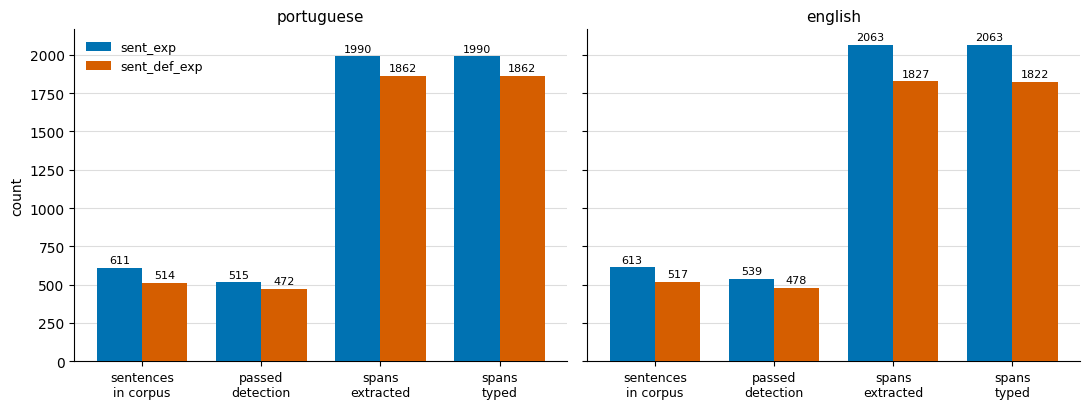

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)

for ax, language in zip(axes, c.LANGUAGE_ORDER):
    sub = inventory[inventory["language"] == language].set_index("condition").reindex(CONDITIONS)
    stages = ["sentences", "detected", "spans_extracted", "spans_typed"]
    x = np.arange(len(stages))
    width = 0.38
    for offset, condition in zip([-width / 2, width / 2], CONDITIONS):
        values = [sub.loc[condition, s] for s in stages]
        bars = ax.bar(x + offset, values, width, label=condition,
                      color=CONDITION_COLORS[condition], zorder=3)
        ax.bar_label(bars, fmt="%d", fontsize=8, padding=2)
    ax.set_xticks(x)
    ax.set_xticklabels(["sentences\nin corpus", "passed\ndetection",
                        "spans\nextracted", "spans\ntyped"], fontsize=9)
    ax.set_title(language, fontsize=11)
    c.style_axis(ax)

axes[0].set_ylabel("count")
axes[0].legend(frameon=False, fontsize=9)
c.save_fig(fig, "06_cascade_funnel")
plt.show()

The funnel shows the volume moving through the pipeline, and already rules out
one candidate explanation: **classification is not where material disappears.**
The span count entering and leaving the classification stage is essentially
unchanged in all four cells, so the stage assigns a type to virtually everything
it is handed. Whatever sets the ceiling happens earlier.

It also shows that the detector is permissive rather than conservative: it
accepts the large majority of sentences. A permissive detector is the safe
failure mode here -- it can only lose a participant by rejecting the sentence
that contains it -- and the next section measures how often that actually
happens.

## 2. Charging every gold participant to a stage

This is the core of the notebook. Every gold participant in the corpus is placed
in exactly one of five buckets:

| bucket | meaning | stage responsible |
|---|---|---|
| `correct` | span found and typed correctly | -- |
| `wrong type` | span found, type wrong | classification |
| `not extracted` | sentence was read, span not returned | extraction |
| `sentence rejected` | detector rejected the containing sentence | detection |
| `unlocated` | gold string not found in any sentence | -- (measurement artefact) |

A gold participant is located by searching for its surface string in the
sentence texts of its own document, case-insensitively. That is a deliberately
simple rule, and the `unlocated` bucket exists to keep it honest: it reports how
often the rule fails rather than silently redistributing those cases. It stays
well under one per cent throughout, so the attribution rests on essentially the
whole gold set.

Types are compared after collapsing the fine-grained `Pl_*` location subtypes
into `Loc` (`_common.COARSE_CLASS_MAP`), for the reason given in `_common.py`:
model outputs never reproduce those subtypes, so scoring them strictly would
charge a label-granularity mismatch to the classification stage.

In [6]:
def attribute_gold(language: str, condition: str) -> pd.DataFrame:
    """Charges each gold participant of one run to the stage that lost it."""
    sub = sentences[(sentences["language"] == language) & (sentences["condition"] == condition)]
    by_doc = {}
    for doc_id, group in sub.groupby("doc_id"):
        by_doc[doc_id] = list(zip(group["text"], group["detected"], group["extracted"]))

    scored = detailed[(detailed["language"] == language) & (detailed["condition"] == condition)]
    gold = scored[scored["result"].isin(["tp", "fn"])]

    rows = []
    for doc_id, token, result, pred_type, annt_type in zip(
        gold["doc_id"], gold["token"], gold["result"], gold["pred_type"], gold["annt_type"]
    ):
        if result == "tp":
            bucket = "correct" if (pd.notna(pred_type) and pred_type == annt_type) else "wrong type"
        else:
            needle = str(token).lower()
            containing = [(detected, spans) for text, detected, spans in by_doc.get(doc_id, [])
                          if needle in text.lower()]
            if not containing:
                bucket = "unlocated"
            elif any(detected for detected, _ in containing):
                # At least one sentence holding this participant was read by the
                # extractor, so the loss belongs to extraction rather than detection.
                bucket = "not extracted"
            else:
                bucket = "sentence rejected"
        rows.append({"language": language, "condition": condition, "doc_id": doc_id,
                     "token": token, "annt_type": annt_type, "bucket": bucket})
    return pd.DataFrame(rows)


attribution = pd.concat(
    [attribute_gold(language, condition)
     for language in c.LANGUAGE_ORDER for condition in CONDITIONS],
    ignore_index=True,
)

BUCKETS = ["correct", "wrong type", "not extracted", "sentence rejected", "unlocated"]
counts = (
    attribution.groupby(["language", "condition", "bucket"]).size()
    .unstack("bucket").reindex(columns=BUCKETS).fillna(0).astype(int)
)
shares = counts.div(counts.sum(axis=1), axis=0)
print(counts.to_string())
print()
shares.round(4)

bucket                   correct  wrong type  not extracted  sentence rejected  unlocated
language   condition                                                                     
english    sent_def_exp      747         120           1623                 77         13
           sent_exp          859         140           1390                189          2
portuguese sent_def_exp      848         128           1509                 83         12
           sent_exp          901         130           1313                234          2



bucket                   correct  wrong type  not extracted  \
language   condition                                          
english    sent_def_exp   0.2895      0.0465         0.6291   
           sent_exp       0.3329      0.0543         0.5388   
portuguese sent_def_exp   0.3287      0.0496         0.5849   
           sent_exp       0.3492      0.0504         0.5089   

bucket                   sentence rejected  unlocated  
language   condition                                   
english    sent_def_exp             0.0298     0.0050  
           sent_exp                 0.0733     0.0008  
portuguese sent_def_exp             0.0322     0.0047  
           sent_exp                 0.0907     0.0008

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\06_miss_attribution_by_stage.pdf


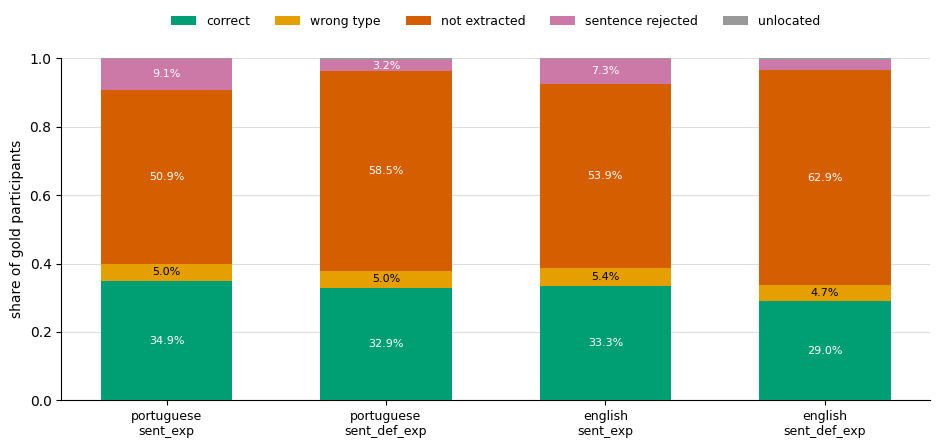

In [7]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))

labels = [f"{language}\n{condition}" for language in c.LANGUAGE_ORDER for condition in CONDITIONS]
index = [(language, condition) for language in c.LANGUAGE_ORDER for condition in CONDITIONS]
x = np.arange(len(index))
bottom = np.zeros(len(index))

for bucket in BUCKETS:
    values = np.array([shares.loc[key, bucket] for key in index])
    ax.bar(x, values, 0.6, bottom=bottom, label=bucket,
           color=STAGE_COLORS[bucket], zorder=3)
    for xi, (value, base) in enumerate(zip(values, bottom)):
        if value >= 0.03:
            ax.text(xi, base + value / 2, f"{value:.1%}", ha="center", va="center",
                    fontsize=8, color="white" if bucket != "wrong type" else "black")
    bottom += values

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("share of gold participants")
ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=9, ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.16))
c.style_axis(ax)
c.save_fig(fig, "06_miss_attribution_by_stage")
plt.show()

### Reading the attribution

The table below collapses the five buckets into the RQ3 question directly: of
everything the pipeline fails to deliver, what share is a **span-level** failure
(the participant was never put on the table) versus an **attribute-level**
failure (it was found, then mislabelled)?

In [8]:
summary = pd.DataFrame({
    "gold": counts.sum(axis=1),
    "delivered_correct": counts["correct"],
    "attribute_loss": counts["wrong type"],
    "span_loss": counts["not extracted"] + counts["sentence rejected"],
    "of_which_detection": counts["sentence rejected"],
    "of_which_extraction": counts["not extracted"],
    "unlocated": counts["unlocated"],
})
losses = summary["attribute_loss"] + summary["span_loss"]
summary["pct_of_loss_span"] = summary["span_loss"] / losses
summary["pct_of_loss_attribute"] = summary["attribute_loss"] / losses
summary["pct_of_span_loss_from_detection"] = summary["of_which_detection"] / summary["span_loss"]
summary.round(4)

gold  delivered_correct  attribute_loss  span_loss  \
language   condition                                                          
english    sent_def_exp  2580                747             120       1700   
           sent_exp      2580                859             140       1579   
portuguese sent_def_exp  2580                848             128       1592   
           sent_exp      2580                901             130       1547   

                         of_which_detection  of_which_extraction  unlocated  \
language   condition                                                          
english    sent_def_exp                  77                 1623         13   
           sent_exp                     189                 1390          2   
portuguese sent_def_exp                  83                 1509         12   
           sent_exp                     234                 1313          2   

                         pct_of_loss_span  pct_of_loss_attribute  \
language   condition                                               
english    sent_def_exp            0.9341                 0.0659   
           sent_exp                0.9186                 0.0814   
portuguese sent_def_exp            0.9256                 0.0744   
           sent_exp                0.9225                 0.0775   

                         pct_of_span_loss_from_detection  
language   condition                                      
english    sent_def_exp                           0.0453  
           sent_exp                               0.1197  
portuguese sent_def_exp                           0.0521  
           sent_exp                               0.1513

## 3. The span/attribute ceiling

The attribution above counts participants. This section converts it into the
metric the rest of the thesis reports, so the size of the ceiling is expressed in
F1 rather than in counts.

Three quantities are compared for each run:

- **span F1** -- the strict span-level score, ignoring types entirely. This is
  what `results.csv` reports for every template (see the note in `_common.py`:
  the evaluator builds its TP/FP/FN sets from span text alone).
- **type-aware F1** -- the same score with a prediction counted correct only when
  both the span and its type match. A span-level TP carrying the wrong type
  becomes simultaneously a false positive for the type it claimed and a false
  negative for the type it should have had.
- **the gap between them** -- the cost of the attribute stage, given the spans
  the pipeline managed to find.

Span F1 is the ceiling: no classification improvement can raise it. The gap is
the room that remains underneath.

In [9]:
ceiling = []
for (language, condition), scored in detailed.groupby(["language", "condition"]):
    span_tp = int((scored["result"] == "tp").sum())
    span_fp = int((scored["result"] == "fp").sum())
    span_fn = int((scored["result"] == "fn").sum())

    tp_rows = scored[scored["result"] == "tp"]
    typed_ok = int((tp_rows["pred_type"].notna() & (tp_rows["pred_type"] == tp_rows["annt_type"])).sum())
    mistyped = span_tp - typed_ok

    def f1(tp, fp, fn):
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        return 2 * precision * recall / (precision + recall) if precision + recall else 0.0

    ceiling.append({
        "language": language,
        "condition": condition,
        "span_f1": f1(span_tp, span_fp, span_fn),
        "type_aware_f1": f1(typed_ok, span_fp + mistyped, span_fn + mistyped),
        "type_accuracy_on_found_spans": typed_ok / span_tp if span_tp else np.nan,
        "span_tp": span_tp, "mistyped": mistyped,
    })

ceiling = pd.DataFrame(ceiling)
ceiling["ceiling_gap"] = ceiling["span_f1"] - ceiling["type_aware_f1"]
ceiling = ceiling.set_index(["language", "condition"]).reindex(index).round(4)
ceiling

span_f1  type_aware_f1  type_accuracy_on_found_spans  \
language   condition                                                            
portuguese sent_exp       0.4512         0.3943                        0.8739   
           sent_def_exp   0.4394         0.3818                        0.8689   
english    sent_exp       0.4303         0.3700                        0.8599   
           sent_def_exp   0.3939         0.3394                        0.8616   

                         span_tp  mistyped  ceiling_gap  
language   condition                                     
portuguese sent_exp         1031       130       0.0569  
           sent_def_exp      976       128       0.0576  
english    sent_exp          999       140       0.0603  
           sent_def_exp      867       120       0.0545

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\06_span_vs_attribute_ceiling_sentence.pdf


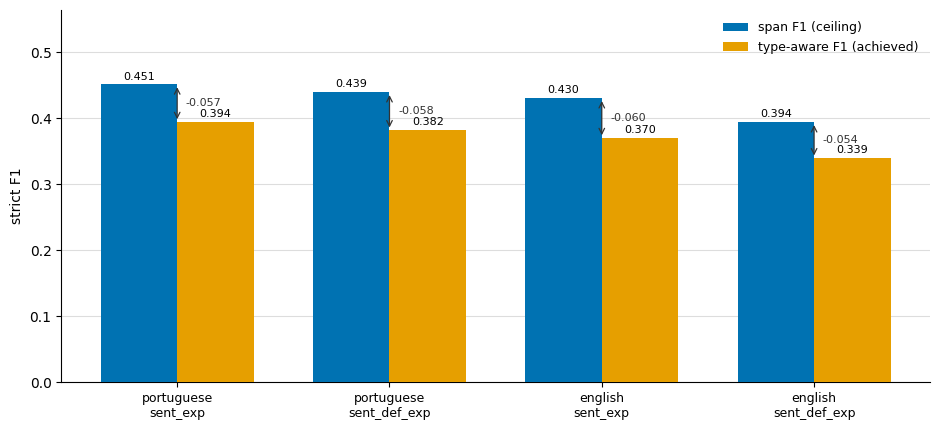

In [10]:
fig, ax = plt.subplots(figsize=(9.5, 4.4))

x = np.arange(len(index))
width = 0.36
span_values = ceiling["span_f1"].to_numpy()
type_values = ceiling["type_aware_f1"].to_numpy()

bars_span = ax.bar(x - width / 2, span_values, width, label="span F1 (ceiling)",
                   color="#0072B2", zorder=3)
bars_type = ax.bar(x + width / 2, type_values, width, label="type-aware F1 (achieved)",
                   color="#E69F00", zorder=3)
ax.bar_label(bars_span, fmt="%.3f", fontsize=8, padding=2)
ax.bar_label(bars_type, fmt="%.3f", fontsize=8, padding=2)

for xi, (span_value, type_value) in enumerate(zip(span_values, type_values)):
    ax.annotate("", xy=(xi, span_value), xytext=(xi, type_value),
                arrowprops=dict(arrowstyle="<->", color="#333333", linewidth=0.9))
    ax.text(xi + 0.04, (span_value + type_value) / 2, f"-{span_value - type_value:.3f}",
            fontsize=8, va="center", ha="left", color="#333333")

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("strict F1")
ax.set_ylim(0, max(span_values) * 1.25)
ax.legend(frameon=False, fontsize=9)
c.style_axis(ax)
c.save_fig(fig, "06_span_vs_attribute_ceiling_sentence")
plt.show()

## 4. Do the self-reported confidences separate right from wrong?

`sent_def_exp` additionally asks the model to attach a confidence to each
decision, logged in `confidence.csv`. If those numbers carried signal, they would
offer a cheap filter: drop low-confidence spans and trade recall for precision.
This section tests whether they do, by comparing the confidence attached to spans
that turned out to be true positives against those that turned out to be false
positives.

**Scope.** Confidences are only recorded for `sent_def_exp`, so `sent_exp` is
absent from this section by construction rather than by choice.

In [11]:
def load_confidence(language: str) -> pd.DataFrame:
    path = overview_dir(language, "sent_def_exp") / "confidence.csv"
    frame = pd.read_csv(path)
    frame["language"] = language
    return frame


confidence = pd.concat([load_confidence(language) for language in c.LANGUAGE_ORDER],
                       ignore_index=True)
print(confidence.groupby(["language", "stage"]).size().to_string())

# Join extraction-stage confidences onto the evaluator's verdict for that span.
outcomes = (
    detailed[(detailed["condition"] == "sent_def_exp") & detailed["result"].isin(["tp", "fp"])]
    [["language", "doc_id", "token", "result"]]
    .drop_duplicates(subset=["language", "doc_id", "token"])
)
extraction = confidence[confidence["stage"] == "extraction"][
    ["language", "doc_id", "item", "confidence"]
].dropna(subset=["item"])
extraction = extraction.rename(columns={"item": "token"}).drop_duplicates(
    subset=["language", "doc_id", "token"]
)
joined = extraction.merge(outcomes, on=["language", "doc_id", "token"], how="inner")

print()
print(f"extraction-stage spans with both a confidence and a verdict: {len(joined)}")
print()
print(joined.groupby(["language", "result"])["confidence"].agg(["count", "mean", "median", "std"]).round(4).to_string())

language    stage         
english     classification    2000
            detection          517
            extraction        2005
portuguese  classification    2024
            detection          514
            extraction        4129

extraction-stage spans with both a confidence and a verdict: 3684

                   count    mean  median     std
language   result                               
english    fp        955  0.8504     0.9  0.1060
           tp        867  0.8636     0.9  0.0991
portuguese fp        861  0.8763     0.9  0.0865
           tp        973  0.8817     0.9  0.0896


Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\06_confidence_calibration.pdf


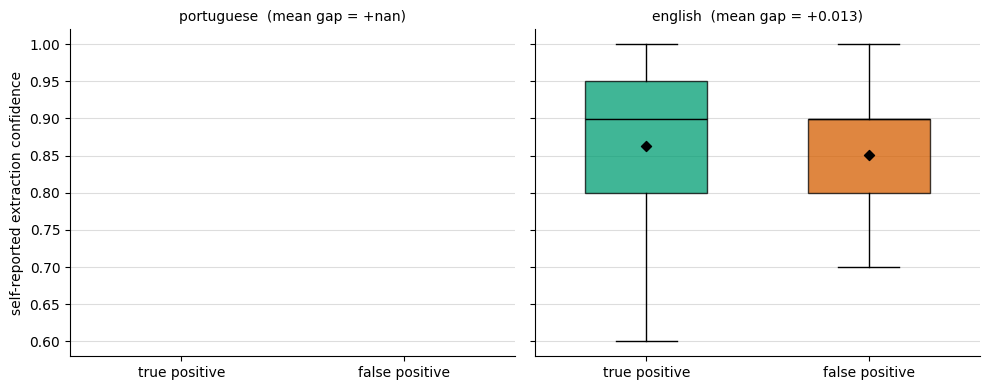

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.0), sharey=True)

for ax, language in zip(axes, c.LANGUAGE_ORDER):
    sub = joined[joined["language"] == language]
    data = [sub[sub["result"] == r]["confidence"].to_numpy() for r in ["tp", "fp"]]
    parts = ax.boxplot(data, patch_artist=True, widths=0.55, showfliers=False)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["true positive", "false positive"])
    for patch, color in zip(parts["boxes"], ["#009E73", "#D55E00"]):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
    for median in parts["medians"]:
        median.set_color("black")
    means = [d.mean() if d.size else np.nan for d in data]
    for xi, mean in enumerate(means, start=1):
        ax.scatter([xi], [mean], marker="D", s=26, color="black", zorder=4)
    ax.set_title(f"{language}  (mean gap = {means[0] - means[1]:+.3f})", fontsize=10)
    c.style_axis(ax)

axes[0].set_ylabel("self-reported extraction confidence")
c.save_fig(fig, "06_confidence_calibration")
plt.show()

## 5. Artefact-integrity notes

Two properties of the stored runs were found while building this notebook. Both
are recorded here because they bear on how the numbers above should be read, and
neither is visible from `results.csv` alone.

In [13]:
# (a) The two conditions do not receive the same input: sent_exp includes the
#     headline as sentence 0, sent_def_exp starts at sentence 1.
headline = []
for language in c.LANGUAGE_ORDER:
    for condition in CONDITIONS:
        sub = sentences[(sentences["language"] == language) & (sentences["condition"] == condition)]
        with_zero = sub[sub["sentence_id"] == 0]["doc_id"].nunique()
        headline.append({
            "language": language, "condition": condition,
            "docs": sub["doc_id"].nunique(),
            "docs_with_sentence_0": with_zero,
            "min_sentence_id": int(sub["sentence_id"].min()),
        })
print("(a) headline (sentence 0) coverage")
print(pd.DataFrame(headline).to_string(index=False))

# How much gold does that headline actually carry that the body does not?
print()
exclusive = []
for language in c.LANGUAGE_ORDER:
    sub = sentences[(sentences["language"] == language) & (sentences["condition"] == "sent_exp")]
    by_doc = {}
    for doc_id, group in sub.groupby("doc_id"):
        by_doc[doc_id] = (
            [t for t, i in zip(group["text"], group["sentence_id"]) if i == 0],
            [t for t, i in zip(group["text"], group["sentence_id"]) if i != 0],
        )
    scored = detailed[(detailed["language"] == language) & (detailed["condition"] == "sent_exp")]
    gold = scored[scored["result"].isin(["tp", "fn"])]
    only_headline = 0
    for doc_id, token in zip(gold["doc_id"], gold["token"]):
        head, body = by_doc.get(doc_id, ([], []))
        needle = str(token).lower()
        if not any(needle in t.lower() for t in body) and any(needle in t.lower() for t in head):
            only_headline += 1
    exclusive.append({"language": language, "gold": len(gold),
                      "recoverable_only_from_headline": only_headline,
                      "share": only_headline / max(len(gold), 1)})
print("    gold participants the headline alone could supply")
print(pd.DataFrame(exclusive).round(4).to_string(index=False))

(a) headline (sentence 0) coverage
  language    condition  docs  docs_with_sentence_0  min_sentence_id
portuguese     sent_exp    97                    97                0
portuguese sent_def_exp    97                     0                1
   english     sent_exp    96                    96                0
   english sent_def_exp    96                     0                1

    gold participants the headline alone could supply
  language  gold  recoverable_only_from_headline  share
portuguese  2580                              10 0.0039
   english  2580                              11 0.0043


In [14]:
# (b) The Portuguese extraction stage occasionally enters a repetition loop,
#     emitting one span thousands of times. The evaluator scores unique spans,
#     so this inflates generation cost, not the reported metrics.
repetition = []
worst = {}
for (language, condition), group in sentences.groupby(["language", "condition"]):
    with_spans = group[group["n_extracted_raw"] > 0]
    raw = int(with_spans["n_extracted_raw"].sum())
    unique = int(sum(len(s) for s in with_spans["extracted"]))
    affected = int((with_spans["n_extracted_raw"] > with_spans["extracted"].map(len)).sum())
    repetition.append({
        "language": language, "condition": condition,
        "sentences_with_spans": len(with_spans),
        "raw_span_emissions": raw, "unique_spans": unique,
        "inflation": raw / max(unique, 1),
        "sentences_affected": affected,
        "share_affected": affected / max(len(with_spans), 1),
    })
    row = with_spans.assign(rep=with_spans["n_extracted_raw"] - with_spans["extracted"].map(len))
    if not row.empty and row["rep"].max() > 0:
        top = row.loc[row["rep"].idxmax()]
        worst[(language, condition)] = (top["doc_id"], int(top["sentence_id"]),
                                        int(top["n_extracted_raw"]), len(top["extracted"]))

print("(b) degenerate repetition in the extraction stage")
print(pd.DataFrame(repetition).round(3).to_string(index=False))
print()
for key, value in worst.items():
    print(f"    worst {key[0]}/{key[1]}: {value[0]} sentence {value[1]} emitted "
          f"{value[2]} spans covering {value[3]} unique surface forms")

(b) degenerate repetition in the extraction stage
  language    condition  sentences_with_spans  raw_span_emissions  unique_spans  inflation  sentences_affected  share_affected
   english sent_def_exp                   476                2005          2005      1.000                   0           0.000
   english     sent_exp                   538                2302          2297      1.002                   4           0.007
portuguese sent_def_exp                   470                4129          2024      2.040                   5           0.011
portuguese     sent_exp                   513                5390          2237      2.409                   7           0.014

    worst english/sent_exp: lusa_78 sentence 3 emitted 6 spans covering 4 unique surface forms
    worst portuguese/sent_def_exp: lusa_1 sentence 1 emitted 2106 spans covering 8 unique surface forms
    worst portuguese/sent_exp: lusa_101 sentence 3 emitted 3149 spans covering 3 unique surface forms


## Synthesis

- Feeds **RQ3**. The sentence-level regime lets every one of the 2,580 gold
  participants be charged to the stage that lost it, which the document-level
  regime cannot do.

- **The ceiling is set by span extraction, not by attribute assignment.** Of
  everything the pipeline fails to deliver, **92.3%** is a span-level failure and
  only **7.7%** an attribute-level one (`portuguese`/`sent_exp`; the range across
  all four runs is 91.9-93.4% span against 6.6-8.1% attribute). The asymmetry is
  the answer to RQ3, and it is not marginal: span failures outnumber type
  failures by roughly twelve to one.

- **Within the span failures, extraction dominates detection.** Detection
  accounts for 12.0-15.1% of span loss under `sent_exp` and only 4.5-5.2% under
  `sent_def_exp`; the remaining 85-95% are sentences the detector correctly
  passed on and from which extraction then failed to return the participant. The
  detector is permissive -- it accepts 84.3-92.5% of sentences -- and permissive
  is the right failure mode, because the only way it can lose a participant is by
  rejecting the sentence containing it.

- **Classification is competent and cheap.** Given a span it has correctly
  located, the model assigns the right coarse type **86.0-87.4%** of the time.
  Converting span F1 into type-aware F1 costs only **0.055-0.060 F1** in every
  run (`portuguese`/`sent_exp`: 0.451 -> 0.394). Perfect typing is therefore worth
  at most six F1 points.

- **The counterfactual makes the imbalance concrete.** For
  `portuguese`/`sent_exp`, 1,313 of the 1,549 missed participants sit in sentences
  the model actually read. Recovering them would lift recall from **0.400 to
  0.908**. No improvement to the classification stage can approach that, because
  classification never sees those participants at all.

- **The self-reported confidences carry no usable signal.** Spans that turn out to
  be true positives are given a mean confidence of 0.864 against 0.850 for false
  positives in English, and 0.882 against 0.876 in Portuguese -- gaps of 0.013 and
  0.005 on a scale where the median of both classes is identical at 0.90. The
  confidences cannot support a precision/recall trade-off, and the extra prompt
  machinery that elicits them is not repaid.

- **Scope caveat.** One model (`qwen3_14b`) at one temperature (0.3). The
  decomposition localises the bottleneck for this configuration; it does not
  establish that the same split holds for the larger models in the document-level
  comparison.

- **Comparability caveat.** The two conditions are not fed identical input:
  `sent_exp` includes the headline as sentence 0 and `sent_def_exp` begins at
  sentence 1. The exposure is bounded and small -- only **0.39%** (Portuguese) and
  **0.43%** (English) of gold participants are recoverable from the headline
  alone, every other one also appearing in the body -- so it cannot account for
  the differences between the two conditions, but any direct `sent_exp` versus
  `sent_def_exp` comparison carries this confound.

- **Generation-cost caveat.** Portuguese extraction intermittently enters a
  repetition loop, emitting a single span thousands of times: `lusa_101`
  sentence 3 returns 3,149 spans covering 3 distinct surface forms. It affects
  1.1-1.4% of Portuguese sentences and inflates raw emissions by 2.0-2.4x, while
  English is essentially clean (1.00x). Because the evaluator scores unique spans
  per document, this costs generation time and tokens without distorting any
  metric reported here.